In [1]:
import os, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# sys.path.append('drought_analysis')
from data_loader import load_drought_data, load_swe_data
from processing import (
    process_drought,
    subset_swe_percent_of_median_peak,
    compute_swe_categories,
)

print("Loading data...")
drought_df = load_drought_data()
ds = load_swe_data()

print("Processing drought metrics...")
drought_wy, drought_melt, drought_diff, drought_month, drought_breaks = process_drought(drought_df)

drought_breaks

Loading data...
Processing drought metrics...


,MapDate,D2_D4_mean,below_thresh,above_thresh,transition
62,2005-03-01,25.3100,True,False,True
93,2007-10-01,23.9900,True,False,True
165,2013-10-01,10.2560,True,False,True
184,2015-05-01,28.1175,True,False,True
230,2019-03-01,11.3375,True,False,True
276,2023-01-01,29.5100,True,False,True


/home/dnash/miniconda3/envs/SEAK-impacts/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,
/home/dnash/miniconda3/envs/SEAK-impacts/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


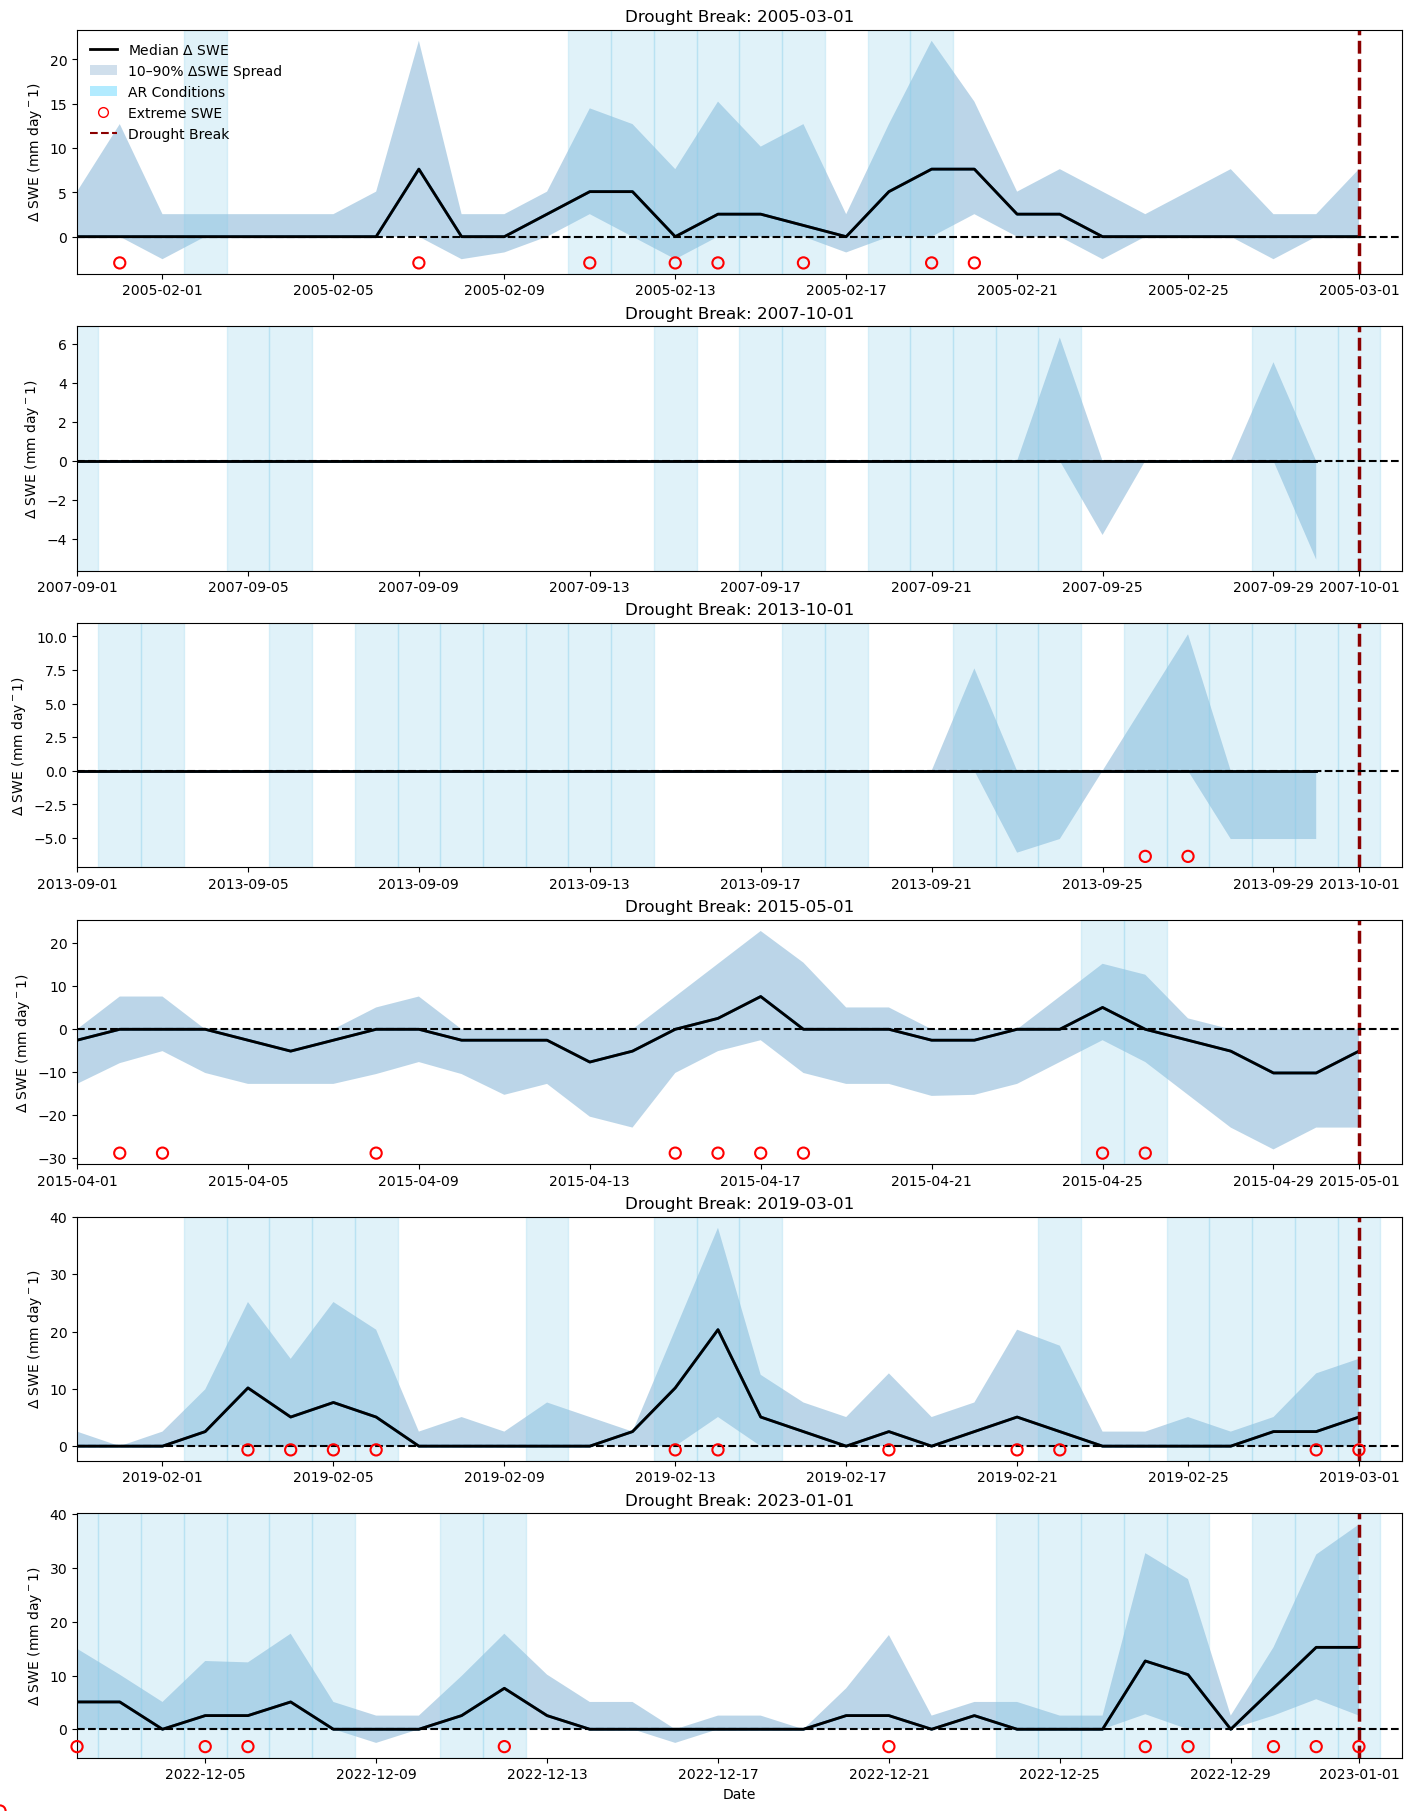

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

# ---------------------------------------------------
# INPUTS
# ---------------------------------------------------

# ds = your xarray dataset
# drought_break = your pandas Series of dates

# Example:
drought_break = pd.to_datetime(drought_breaks['MapDate'])
label = r'$\Delta$ SWE'
# ---------------------------------------------------
# PLOT SETTINGS
# ---------------------------------------------------

n_events = len(drought_break)

fig, axes = plt.subplots(
    n_events,
    1,
    figsize=(14, 3 * n_events),
    sharex=False,
    constrained_layout=True
)

if n_events == 1:
    axes = [axes]

# ---------------------------------------------------
# LOOP THROUGH DROUGHT BREAK EVENTS
# ---------------------------------------------------

for ax, break_date in zip(axes, drought_break):

    break_date = pd.Timestamp(break_date)

    # One month before drought break
    start_date = break_date - pd.Timedelta(days=30)

    subset = ds.sel(time=slice(start_date, break_date))

    # ------------------------------------------------
    # Plot station spread
    # ------------------------------------------------

    # for station in subset.station.values:

        # ax.plot(
        #     subset.time,
        #     subset["SWE"].sel(station=station),
        #     color="lightgray",
        #     linewidth=0.7,
        #     alpha=0.5
        # )

    p10 = subset["SWE"].quantile(0.1, dim="station")
    p90 = subset["SWE"].quantile(0.9, dim="station")
    median = subset["SWE"].median(dim="station")
    
    ax.fill_between(
        subset.time.values,
        p10.values,
        p90.values,
        alpha=0.3
    )
    
    ax.plot(subset.time, median, linewidth=2)

    # ------------------------------------------------
    # Plot basin median
    # ------------------------------------------------

    basin_median = subset["SWE"].median(dim="station")

    ax.plot(
        subset.time,
        basin_median,
        color="black",
        linewidth=2,
        label=f"Median {label}"
    )

    # ------------------------------------------------
    # AR DAYS
    # ------------------------------------------------

    # Fraction of stations experiencing AR
    ar_frac = subset["AR"].mean(dim="station")

    ar_days = subset.time.where(ar_frac > 0.5, drop=True)

    for day in ar_days.values:
        ax.axvspan(
            pd.Timestamp(day) - pd.Timedelta(hours=12),
            pd.Timestamp(day) + pd.Timedelta(hours=12),
            color="skyblue",
            alpha=0.25
        )

    # --------------------------------------------
    # Extreme SWE days
    # --------------------------------------------
    extreme_frac = subset["extreme"].mean(dim="station")

    extreme_days = subset.time.where(
        extreme_frac > 0.01,
        drop=True
    )

    # Place markers slightly above x-axis
    ymin, ymax = ax.get_ylim()

    marker_y = ymin + 0.03 * (ymax - ymin)

    ax.scatter(
        extreme_days,
        np.full(len(extreme_days), marker_y),
        facecolor='none',
        edgecolor='red',
        linewidth=1.5,
        s=65,
        zorder=5,
        clip_on=False
    )

    # ------------------------------------------------
    # Formatting
    # ------------------------------------------------

    ax.axvline(
        break_date,
        color="darkred",
        linestyle="--",
        linewidth=2.5,
        label="Drought Break"
    )

    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1.5,
    )

    ax.set_ylabel(f'{label} (mm day$^{-1}$)')
    ax.set_title(
        f"Drought Break: {break_date.strftime('%Y-%m-%d')}"
    )

    # ax.grid(alpha=0.3)

    ax.set_xlim(start_date, break_date + pd.Timedelta(days=1))

# ---------------------------------------------------
# Custom Legend
# ---------------------------------------------------

legend_handles = [

    Line2D(
        [0], [0],
        color='black',
        linewidth=2,
        label=f'Median {label}'
    ),

    Patch(
        facecolor='steelblue',
        alpha=0.25,
        label='10–90% ΔSWE Spread'
    ),

    Patch(
        facecolor='deepskyblue',
        alpha=0.30,
        label='AR Conditions'
    ),

    Line2D(
        [0], [0],
        marker='o',
        linestyle='None',
        markerfacecolor='none',
        markeredgecolor='red',
        markersize=7,
        label='Extreme SWE'
    ),

    Line2D(
        [0], [0],
        color='darkred',
        linestyle='--',
        linewidth=1.5,
        label='Drought Break'
    )
]

axes[0].legend(
    handles=legend_handles,
    loc='upper left',
    frameon=False
)

# ---------------------------------------------------
# Shared formatting
# ---------------------------------------------------
plt.xlabel("Date")
plt.show()

fname = '../figs/drought_break_time_series'
fmt = 'png'
fig.savefig('%s.%s' %(fname, fmt), bbox_inches='tight', dpi=fig.dpi)

In [7]:
drought_df = load_drought_data()
df = drought_df.copy()
# Compute D2+ area
df["D2_D4_total"] = df["D2"] + df["D3"] + df["D4"]

# Ensure chronological order within WY
df = df.sort_values("MapDate")
df

,HUCId,MapDate,HUC,HUCLevel,None,D0,D1,D2,D3,D4,ValidStart,ValidEnd,StatisticFormatID,D2_D4_total
1304,14,2000-01-04,Upper Colorado,2,100.00,0.00,0.00,0.00,0.00,0.0,2000-01-04,2000-01-10,2,0.00
1303,14,2000-01-11,Upper Colorado,2,51.72,48.28,0.00,0.00,0.00,0.0,2000-01-11,2000-01-17,2,0.00
1302,14,2000-01-18,Upper Colorado,2,41.38,58.62,0.00,0.00,0.00,0.0,2000-01-18,2000-01-24,2,0.00
1301,14,2000-01-25,Upper Colorado,2,41.38,58.62,0.00,0.00,0.00,0.0,2000-01-25,2000-01-31,2,0.00
1300,14,2000-02-01,Upper Colorado,2,44.57,55.43,0.00,0.00,0.00,0.0,2000-02-01,2000-02-07,2,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4,14,2024-12-03,Upper Colorado,2,39.80,40.59,17.40,2.18,0.02,0.0,2024-12-03,2024-12-09,2,2.20
3,14,2024-12-10,Upper Colorado,2,39.80,40.60,17.40,1.75,0.45,0.0,2024-12-10,2024-12-16,2,2.20
2,14,2024-12-17,Upper Colorado,2,39.73,43.70,14.36,1.75,0.45,0.0,2024-12-17,2024-12-23,2,2.20
1,14,2024-12-24,Upper Colorado,2,31.99,48.04,17.60,1.93,0.45,0.0,2024-12-24,2024-12-30,2,2.38


In [8]:
month_df = df.groupby(pd.PeriodIndex(df['MapDate'], freq="M"))['D2_D4_total'].mean()
month_df = month_df.to_frame(name="D2_D4_mean").reset_index()
month_df['MapDate'] = month_df['MapDate'].dt.to_timestamp()
month_df

,MapDate,D2_D4_mean
0,2000-01-01,0.0000
1,2000-02-01,0.0000
2,2000-03-01,0.0000
3,2000-04-01,0.0000
4,2000-05-01,0.0000
...,...,...
295,2024-08-01,0.0100
296,2024-09-01,0.0100
297,2024-10-01,0.9600
298,2024-11-01,1.3325


In [9]:
# Assume df_long already filtered to one division and sorted
df = month_df.copy()

# Boolean flags
df['below_thresh'] = df['D2_D4_mean'] < 30.
df['above_thresh'] = df['D2_D4_mean'] >= 30.

# Identify transitions from drought → non-drought
df['transition'] = (df['above_thresh'].shift(1) == True) & (df['below_thresh'] == True)

# Find all candidate break indices
candidate_idx = df.index[df['transition']].tolist()

# Confirm persistence ≥ 6 months
drought_breaks = []

for idx in candidate_idx:
    # Look forward 6 months (including current)
    window = df.loc[idx: idx+5, 'below_thresh']
    # print(window)
    
    if len(window) == 6 and window.all():
        drought_breaks.append(idx)

# Extract event dataframe
df_breaks = df.loc[drought_breaks].copy()
df_breaks

,MapDate,D2_D4_mean,below_thresh,above_thresh,transition
62,2005-03-01,25.3100,True,False,True
93,2007-10-01,23.9900,True,False,True
165,2013-10-01,10.2560,True,False,True
184,2015-05-01,28.1175,True,False,True
230,2019-03-01,11.3375,True,False,True
276,2023-01-01,29.5100,True,False,True


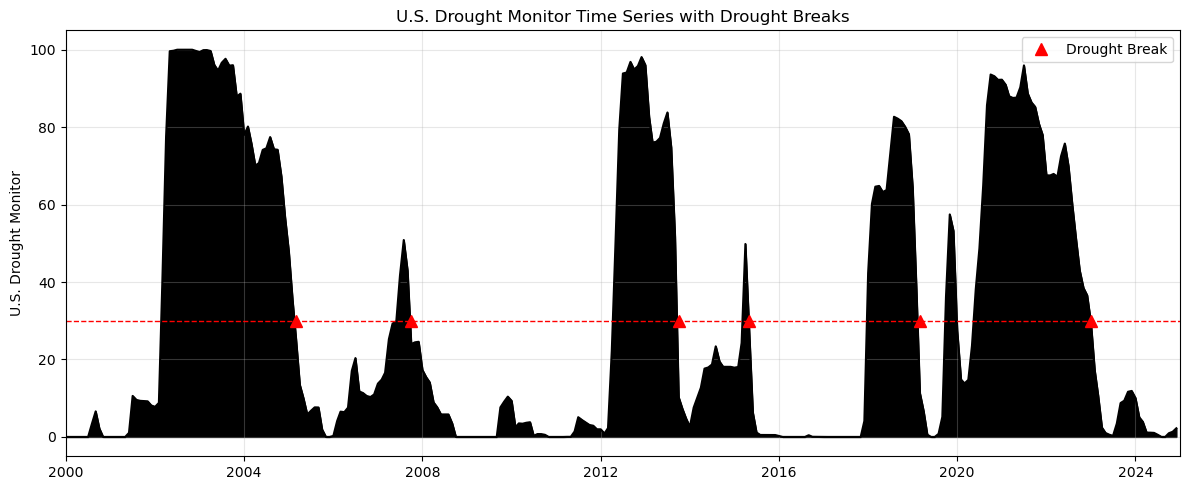

In [10]:


fig, ax = plt.subplots(figsize=(12, 5))

# Main line
ax.plot(df['MapDate'], df['D2_D4_mean'], color='black', linewidth=1.5)

# Fill to zero
ax.fill_between(
    df['MapDate'],
    df['D2_D4_mean'],
    0,
    where=(df['D2_D4_mean'] >= 0),
    interpolate=True,
    color='black'
)

# Reference line at -2
ax.axhline(30., color='red', linestyle='--', linewidth=1)

# Drought break markers (triangles at -2 line)
ax.plot(
    df_breaks['MapDate'],
    [30]*len(df_breaks),
    '^',
    color='red',
    markersize=8,
    label='Drought Break'
)

# Formatting
ax.set_ylabel('U.S. Drought Monitor')
ax.set_title('U.S. Drought Monitor Time Series with Drought Breaks')
ax.grid(True, alpha=0.3)
ax.legend()
ax.set_xlim(pd.to_datetime('2000-01-01'), pd.to_datetime('2024-12-31'))

plt.tight_layout()
plt.show()

In [5]:
WY = 2013
idx = (df['MapDate'] >= f'{WY-1}-10-01') & (df['MapDate'] <= f'{WY}-09-30')
tmp = df.loc[idx]
tmp

,HUCId,MapDate,HUC,HUCLevel,None,D0,D1,D2,D3,D4,ValidStart,ValidEnd,StatisticFormatID,D2_D4_total
639,14,2012-10-02,Upper Colorado,2,0.00,0.00,4.96,48.68,46.36,0.00,2012-10-02,2012-10-08,2,95.04
638,14,2012-10-09,Upper Colorado,2,0.00,0.00,5.11,48.53,46.36,0.00,2012-10-09,2012-10-15,2,94.89
637,14,2012-10-16,Upper Colorado,2,0.00,0.00,5.17,49.80,45.03,0.00,2012-10-16,2012-10-22,2,94.83
636,14,2012-10-23,Upper Colorado,2,0.00,0.00,5.19,47.74,47.06,0.00,2012-10-23,2012-10-29,2,94.80
635,14,2012-10-30,Upper Colorado,2,0.00,0.00,5.19,48.25,46.56,0.00,2012-10-30,2012-11-05,2,94.81
634,14,2012-11-06,Upper Colorado,2,0.00,0.00,5.03,48.41,46.56,0.00,2012-11-06,2012-11-12,2,94.97
633,14,2012-11-13,Upper Colorado,2,0.00,0.00,4.90,51.84,43.26,0.00,2012-11-13,2012-11-19,2,95.10
632,14,2012-11-20,Upper Colorado,2,0.00,0.00,4.90,51.84,43.26,0.00,2012-11-20,2012-11-26,2,95.10
631,14,2012-11-27,Upper Colorado,2,0.00,0.00,2.00,53.12,44.88,0.00,2012-11-27,2012-12-03,2,98.00
630,14,2012-12-04,Upper Colorado,2,0.00,0.00,1.99,52.73,45.27,0.00,2012-12-04,2012-12-10,2,98.00


<Axes: >

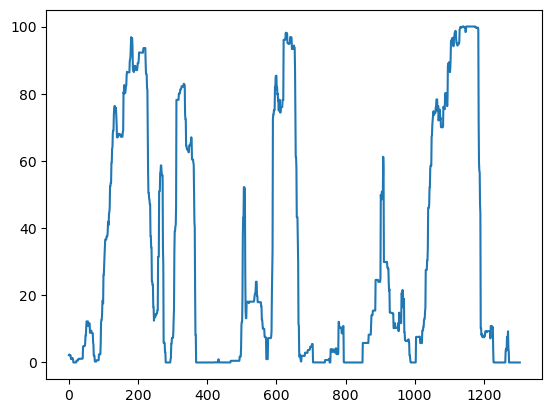

In [6]:
df['D2_D4_total'].plot()

In [10]:
fname = '../data/climdiv-pdsist-v1.0.0-20260305'
# Read as whitespace-delimited
df = pd.read_csv(fname, sep='\s+', header=None)
cols = ['id_year'] + [f'month_{i:02d}' for i in range(1, 13)]
df.columns = cols
df['year'] = df['id_year'].astype(str).str[-4:].astype(int)
df['division'] = df['id_year'].astype(str).str[:-4].astype(int)
idx = df['division'] == 205005
df = df.loc[idx]
df_long = df.melt(
    id_vars=['division', 'year'],
    value_vars=[f'month_{i:02d}' for i in range(1, 13)],
    var_name='month',
    value_name='pdsi'
)

# Convert month to integer
df_long['month'] = df_long['month'].str[-2:].astype(int)

df_long['date'] = pd.to_datetime(dict(
    year=df_long['year'],
    month=df_long['month'],
    day=1
))

df_long['pdsi'] = df_long['pdsi'].replace(-99.99, pd.NA)
df_long['pdsi'] = pd.to_numeric(df_long['pdsi'], errors='coerce')
df_long = df_long.sort_values(by="date", axis=0)
idx = (df_long['date'] <= "2026-02-01")
df_long = df_long.loc[idx]
df_long = df_long.reset_index()
df_long

<>:3: SyntaxWarning: invalid escape sequence '\s'
<>:3: SyntaxWarning: invalid escape sequence '\s'
/scratch/dnash/job_3478611/ipykernel_4127819/2583554942.py:3: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv(fname, sep='\s+', header=None)


,index,division,year,month,pdsi,date
0,0,205005,1895,1,1.85,1895-01-01
1,132,205005,1895,2,2.73,1895-02-01
2,264,205005,1895,3,2.67,1895-03-01
3,396,205005,1895,4,1.70,1895-04-01
4,528,205005,1895,5,1.84,1895-05-01
...,...,...,...,...,...,...
1569,1318,205005,2025,10,-5.02,2025-10-01
1570,1450,205005,2025,11,-5.35,2025-11-01
1571,1582,205005,2025,12,-5.48,2025-12-01
1572,131,205005,2026,1,-5.83,2026-01-01


In [11]:
# Assume df_long already filtered to one division and sorted
df = df_long.sort_values('date').copy()

# Boolean flags
df['below_thresh'] = df['pdsi'] < -2
df['above_thresh'] = df['pdsi'] >= -2

# Identify transitions from drought → non-drought
df['transition'] = (df['below_thresh'].shift(1) == True) & (df['above_thresh'] == True)

# Find all candidate break indices
candidate_idx = df.index[df['transition']].tolist()

# Confirm persistence ≥ 6 months
drought_breaks = []

for idx in candidate_idx:
    # Look forward 6 months (including current)
    window = df.loc[idx: idx+5, 'above_thresh']
    # print(window)
    
    if len(window) == 6 and window.all():
        drought_breaks.append(idx)

# Extract event dataframe
df_breaks = df.loc[drought_breaks].copy()


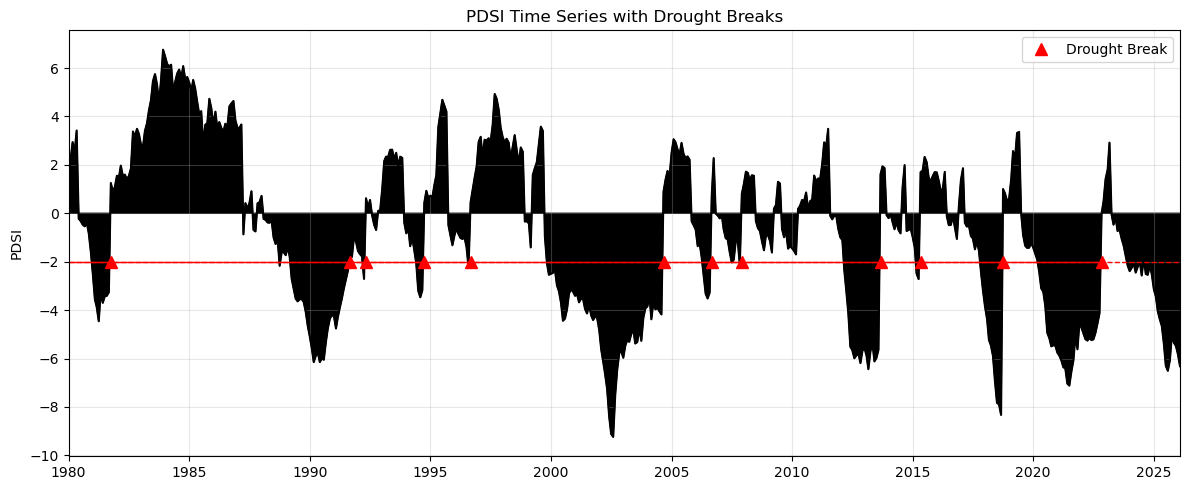

In [12]:


fig, ax = plt.subplots(figsize=(12, 5))

# Main line
ax.plot(df['date'], df['pdsi'], color='black', linewidth=1.5)

# Fill to zero
ax.fill_between(
    df['date'],
    df['pdsi'],
    0,
    where=(df['pdsi'] >= 0),
    interpolate=True,
    color='black'
)

ax.fill_between(
    df['date'],
    df['pdsi'],
    0,
    where=(df['pdsi'] < 0),
    interpolate=True,
    color='black'
)

# Reference line at -2
ax.axhline(-2, color='red', linestyle='--', linewidth=1)

# Drought break markers (triangles at -2 line)
ax.plot(
    df_breaks['date'],
    [-2]*len(df_breaks),
    '^',
    color='red',
    markersize=8,
    label='Drought Break'
)

# Optional: connect markers with a line
ax.plot(
    df_breaks['date'],
    [-2]*len(df_breaks),
    color='red',
    linewidth=1
)

# Formatting
ax.set_ylabel('PDSI')
ax.set_title('PDSI Time Series with Drought Breaks')
ax.grid(True, alpha=0.3)
ax.legend()
ax.set_xlim(pd.to_datetime('1980-01-01'), pd.to_datetime('2026-02-01'))

plt.tight_layout()
plt.show()

In [13]:
df_breaks

,index,division,year,month,pdsi,date,below_thresh,above_thresh,transition
97,140,205005,1903,2,0.16,1903-02-01,False,True,True
121,142,205005,1905,2,0.70,1905-02-01,False,True,True
189,1203,205005,1910,10,0.28,1910-10-01,False,True,True
278,287,205005,1918,3,-1.70,1918-03-01,False,True,True
296,1080,205005,1919,9,-0.01,1919-09-01,False,True,True
440,1092,205005,1931,9,0.14,1931-09-01,False,True,True
459,434,205005,1933,4,-1.60,1933-04-01,False,True,True
484,568,205005,1935,5,-1.59,1935-05-01,False,True,True
498,833,205005,1936,7,0.31,1936-07-01,False,True,True
548,1101,205005,1940,9,1.30,1940-09-01,False,True,True


In [14]:
ds = load_swe_data()
ds = ds.sel(time=slice('2013-09-05', '2013-09-21'))
ds

<xarray.Dataset> Size: 45kB
Dimensions:     (time: 17, station: 90)
Coordinates:
  * time        (time) datetime64[ns] 136B 2013-09-05 2013-09-06 ... 2013-09-21
  * station     (station) <U11 4kB '317:WY:SNTL' '335:CO:SNTL' ... '874:CO:SNTL'
    latitude    (station) float64 720B ...
    longitude   (station) float64 720B ...
    elevation   (station) float64 720B ...
    water_year  (time) int64 136B ...
    lat         (station) float64 720B ...
    lev         float64 8B ...
    ens         float64 8B ...
    lon         (station) float64 720B ...
Data variables:
    SWE         (time, station) float64 12kB ...
    extreme     (time, station) int64 12kB ...
    AR          (time, station) float64 12kB ...

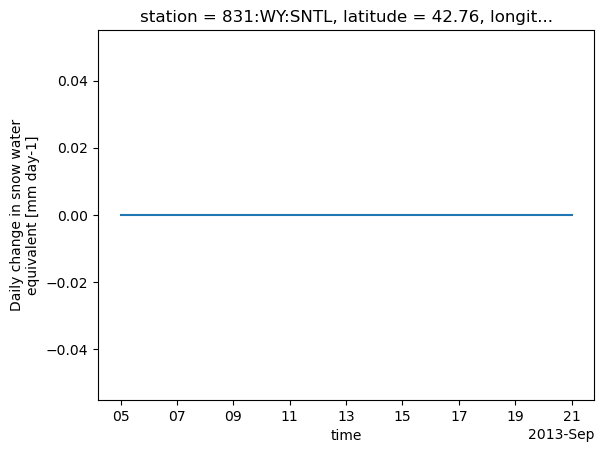

In [21]:
station = 80
ds.isel(station=station).SWE.plot()

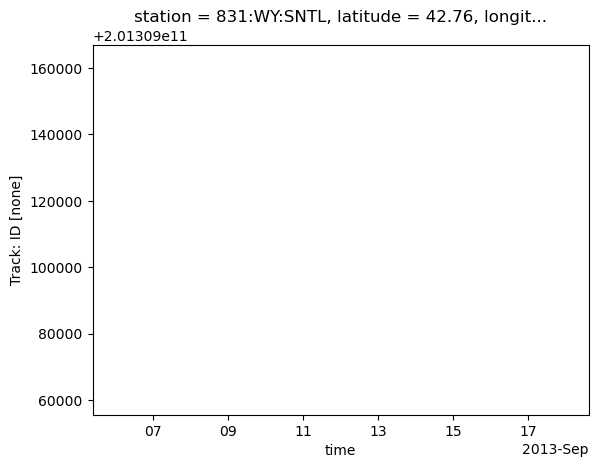

In [22]:
ds.isel(station=station).AR.plot()

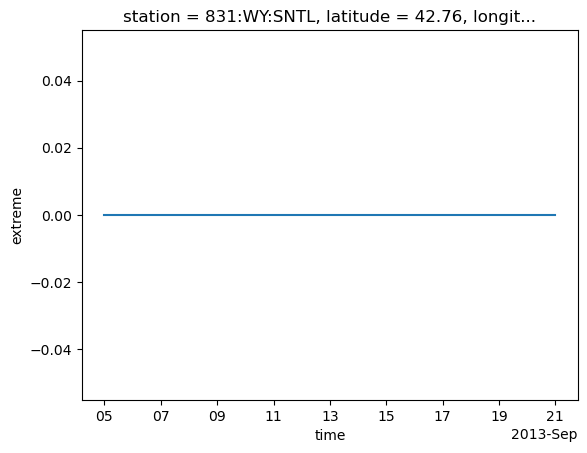

In [23]:
ds.isel(station=station).extreme.plot()